# Ablaciones ECoG (BCI IV-4): Colab desde VS Code

Campaña de **135 entrenamientos**: 9 configuraciones × 3 sujetos × 5 folds. P2 y P4 se verifican por equivalencia con P1 y no se entrenan. Especificación completa: `docs/plan_experimental.md`.

Después, una **campaña complementaria de 30 entrenamientos** (A5a y A5b, descomposición de A5) en la sección 11; se decidió con resultados parciales y se reporta aparte (sección 12 del plan).

Este notebook se abre en **VS Code** y se ejecuta en un **servidor de Colab** mediante la extensión oficial *Google Colab*. El archivo `.ipynb` vive en tu repositorio local, pero cada celda corre en la máquina remota: rutas como `/content/...` y el código del paquete existen allí, no en tu PC.

**Preparación (una vez)**
1. Instala la extensión *Google Colab* en VS Code e inicia sesión con tu cuenta de Google.
2. Sube `sub1_comp.mat`, `sub2_comp.mat` y `sub3_comp.mat` a una carpeta de Google Drive (`DATA_DIR`).
3. Haz `git push` del repositorio a GitHub, idealmente con una etiqueta fija para la campaña (`GIT_REF`).

**Conectar el kernel**
- Abre este notebook en VS Code → *Select Kernel* (arriba a la derecha) → *Colab* → *New Colab Server* → elige una máquina con **GPU**.
- Usa la misma clase de GPU en toda la campaña: TF32 está permitido y cambia ligeramente la aritmética entre GPUs.

**Importante**
- **El código del paquete viene del commit clonado en el servidor**, no de tu carpeta local. Si cambias `src/`, haz commit y push y vuelve a ejecutar la celda 3. Los cambios en este notebook sí se aplican directamente.
- La extensión no admite *Secrets* de Colab (`userdata.get`). Si el repo es privado, la celda 3 pide el token con un cuadro de entrada y no lo guarda en el notebook.
- Mantén VS Code abierto y conectado durante la campaña. Si el servidor se recicla, se pierde lo que haya en `/content`, pero los resultados están en Drive: abre un servidor nuevo, ejecuta las celdas 1–3 y luego la 7 (o la 11 en la campaña complementaria). Las corridas completadas se saltan, la interrumpida se reentrena desde cero y las fallidas se conservan para diagnóstico.
- Con la terminal experimental de la extensión (*Colab: Open Terminal*) puedes seguir el log con `tail -f`.
- **Varias sesiones en paralelo:** cada servidor debe usar `SUBJECTS`/`FOLDS` disjuntos sobre el mismo `RESULTS_DIR`, por ejemplo uno por sujeto.

## 1. GPU y Google Drive
Si `drive.mount` no lanza el inicio de sesión, usa el comando de VS Code *Colab: Mount Google Drive to Server...*, que inserta la celda de montaje.

In [14]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 2. Configuración

In [15]:
GIT_URL = "https://github.com/SaulRodas/ECoG_Architectures_Exploration.git"  # ← tu repositorio ("" = código subido a mano)
GIT_REF = "main"           # recomendado: una etiqueta fija para toda la campaña, p. ej. "campana-v1"
PRIVATE_REPO = False       # True → la celda 3 pide un token de GitHub de solo lectura
REPO_DIR = "/content/ECoG_Architectures_Exploration"   # carpeta del código EN EL SERVIDOR

DRIVE_ROOT = "/content/drive/MyDrive"
DATA_DIR = f"{DRIVE_ROOT}/ECoG_Architectures_Exploration/data/raw"             # contiene sub1_comp.mat, sub2_comp.mat, sub3_comp.mat
RESULTS_DIR = f"{DRIVE_ROOT}/ECoG_Architectures_Exploration/results"

SUBJECTS = ["S1", "S2", "S3"]
FOLDS = ["B1", "B2", "B3", "B4", "B5"]
VARIANTS = ["P0", "P1", "P3", "P5", "A1", "A2", "A3", "A4", "A5"]   # campaña principal (135); acotable, p. ej. ["P0", "A3"]
EXTRA_VARIANTS = ["A5a", "A5b"]   # campaña complementaria (sección 11): 30 entrenamientos

import os
missing = [f for f in ("sub1_comp.mat", "sub2_comp.mat", "sub3_comp.mat") if not os.path.exists(f"{DATA_DIR}/{f}")]
print("datos OK" if not missing else f"faltan en {DATA_DIR}: {missing}")
os.makedirs(RESULTS_DIR, exist_ok=True)

datos OK


## 3. Código y dependencias en el servidor
- **Opción A (recomendada):** se clona `GIT_URL` en `GIT_REF`. El commit queda registrado en cada corrida.
- **Opción B:** con `GIT_URL = ""`, sube el código con clic derecho sobre `src`, `scripts`, `configs`, `tests` y `pyproject.toml` → *Upload to Colab*. Quedan en `/content/`, así que pon `REPO_DIR = "/content"`. Sin `.git` no queda commit registrado.

El token (si `PRIVATE_REPO = True`) se pide con un cuadro de entrada y no se imprime ni se guarda en la URL del remoto.

In [3]:
import base64, getpass, subprocess, sys

TOKEN = getpass.getpass("Token de GitHub (solo lectura): ") if (GIT_URL and PRIVATE_REPO) else None

def git(*args, cwd=None):
    cmd = ["git"]
    if TOKEN:
        basic = base64.b64encode(f"x-access-token:{TOKEN}".encode()).decode()
        cmd += ["-c", f"http.extraHeader=Authorization: Basic {basic}"]
    out = subprocess.run(cmd + list(args), cwd=cwd, capture_output=True, text=True)
    if out.returncode != 0:
        message = out.stderr.replace(TOKEN, "***") if TOKEN else out.stderr
        raise RuntimeError(f"git {args[0]} falló: {message[-800:]}")
    return out.stdout.strip()

if GIT_URL:
    if not os.path.exists(f"{REPO_DIR}/.git"):
        git("clone", "--quiet", GIT_URL, REPO_DIR)
    git("fetch", "--quiet", "--tags", "origin", cwd=REPO_DIR)
    git("checkout", "--quiet", GIT_REF, cwd=REPO_DIR)
    if git("rev-parse", "--abbrev-ref", "HEAD", cwd=REPO_DIR) != "HEAD":   # rama (no etiqueta): actualizar
        git("pull", "--quiet", "--ff-only", cwd=REPO_DIR)
    print("commit:", git("log", "-1", "--format=%h %s (%ci)", cwd=REPO_DIR))
else:
    assert os.path.exists(f"{REPO_DIR}/src/ecog_ablations"), f"no está el código en {REPO_DIR} (¿Upload to Colab?)"
    print("usando código subido en", REPO_DIR)

!pip install -q "mne>=1.6"

sys.path.insert(0, f"{REPO_DIR}/src")
from ecog_ablations.config import load_config
from ecog_ablations import reporting
CFG = load_config(f"{REPO_DIR}/configs/experiment.yaml")
print("configuración:", CFG["_path"], "| retardo", CFG["preprocessing"]["delay_ms"], "ms | TF32", CFG["runtime"]["allow_tf32"])

commit: 9222385 Init (2026-10-27 20:07:18 -0600)
configuración: /content/ECoG_Architectures_Exploration/configs/experiment.yaml | retardo 20 ms | TF32 True


## 4. Comprobaciones mínimas (`pytest`)
Incluyen la lectura de los tres `.mat`, la equivalencia de la DSP con MNE las 8 arquitecturas (A0–A5, A5a, A5b) y los contrastes de la sección 11.

In [4]:
!cd "{REPO_DIR}" && ECOG_DATA_DIR="{DATA_DIR}" python -m pytest -q 2>&1 | tail -5

......................................                                   [100%]
38 passed in 29.28s


## 5. Control de calidad previo
Canales excluidos, fase del guante, recortes por canal y fold, señal cruda frente a limpia y respuesta de los filtros.

2026-10-28 02:13:29 INFO [S1] control de calidad listo: 61 canales usados
2026-10-28 02:13:39 INFO [S2] control de calidad listo: 46 canales usados
2026-10-28 02:13:52 INFO [S3] control de calidad listo: 63 canales usados
control de calidad en /content/drive/MyDrive/ECoG_Architectures_Exploration/results/quality


,subject,n_channels_raw,excluded,n_channels_used
0,S1,62,54,61
1,S2,48,20 37,46
2,S3,64,49,63


,subject,n_changes,aligned_fraction
0,S1,9745,1.0
1,S2,9451,1.0
2,S3,9929,1.0


,subject,fold,clean_finite,glove_finite,clip_fraction_train,clip_fraction_val,mad_floored_channels
0,S1,B1,True,True,0.0,0.0,0
1,S1,B2,True,True,0.0,0.0,0
2,S1,B3,True,True,0.0,0.0,0
3,S1,B4,True,True,0.0,0.0,0
4,S1,B5,True,True,0.0,0.0,0
5,S2,B1,True,True,0.0,0.0,0
6,S2,B2,True,True,0.0,0.0,0
7,S2,B3,True,True,0.0,0.0,0
8,S2,B4,True,True,0.0,0.0,0
9,S2,B5,True,True,0.0,0.0,0


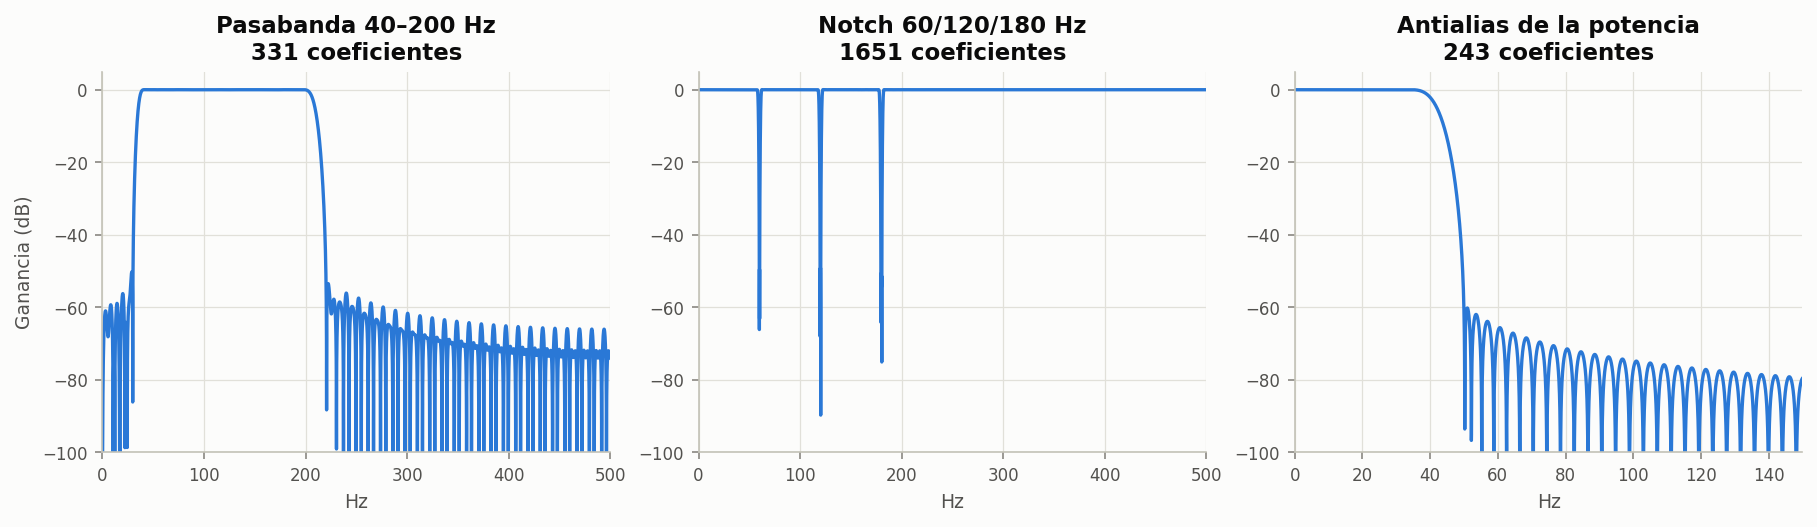

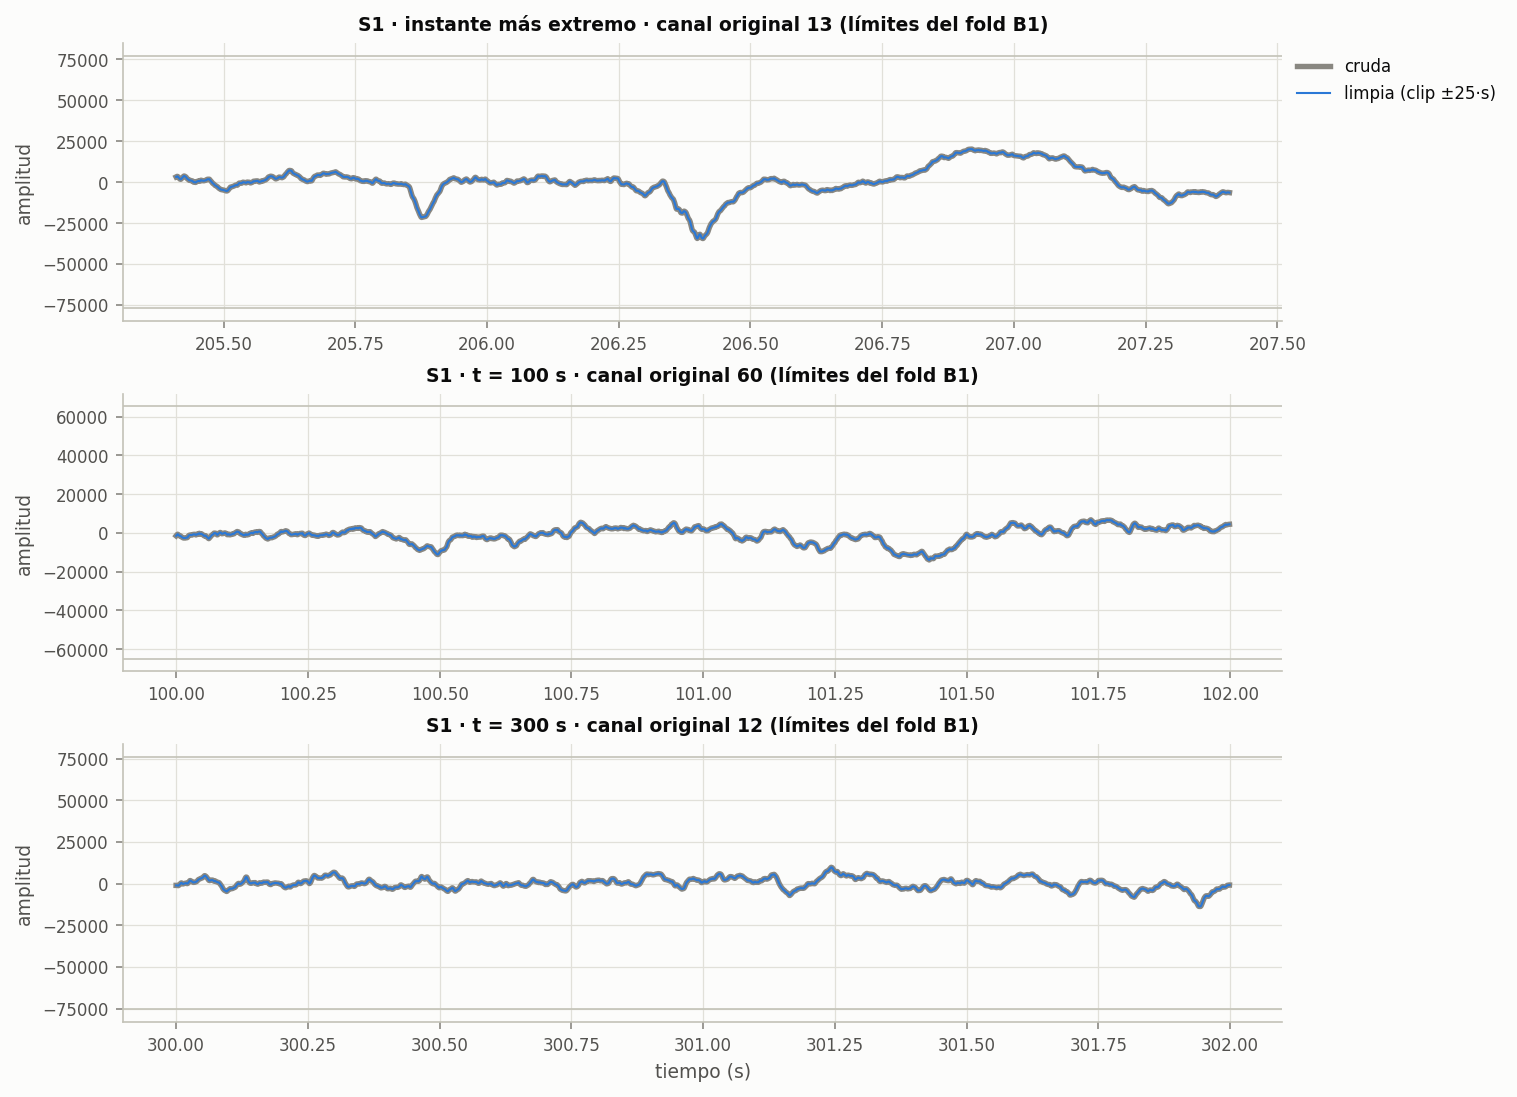

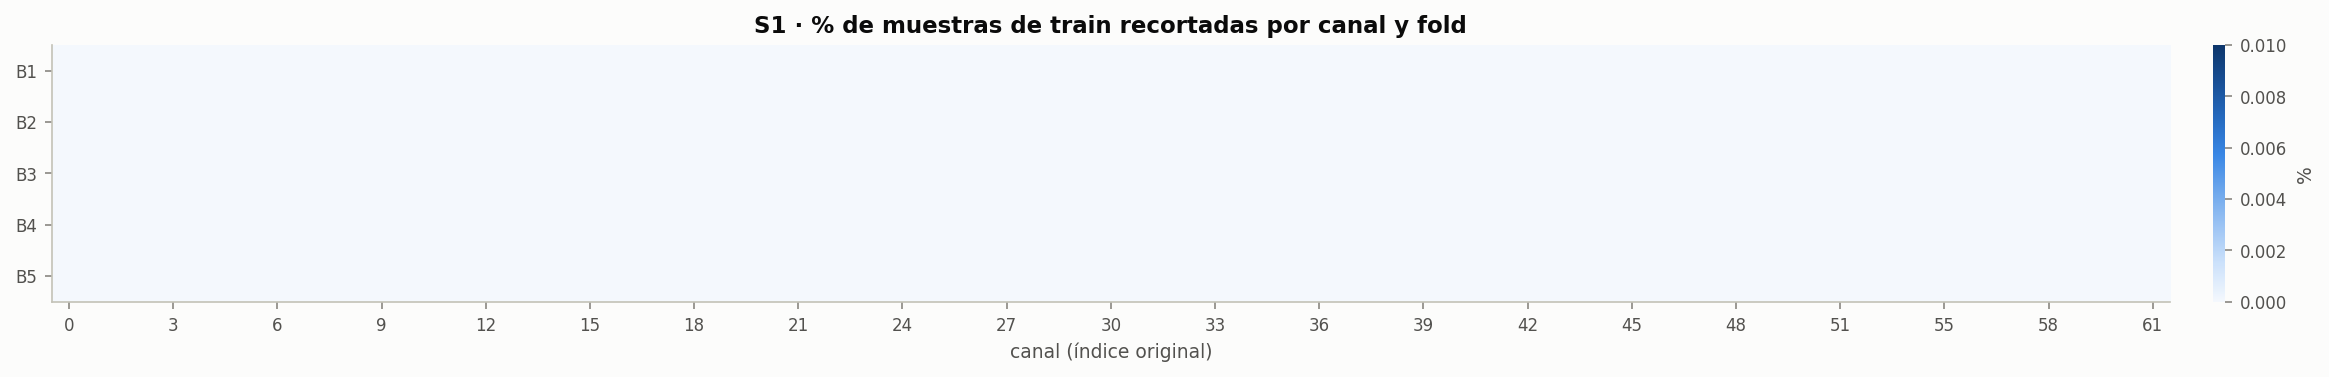

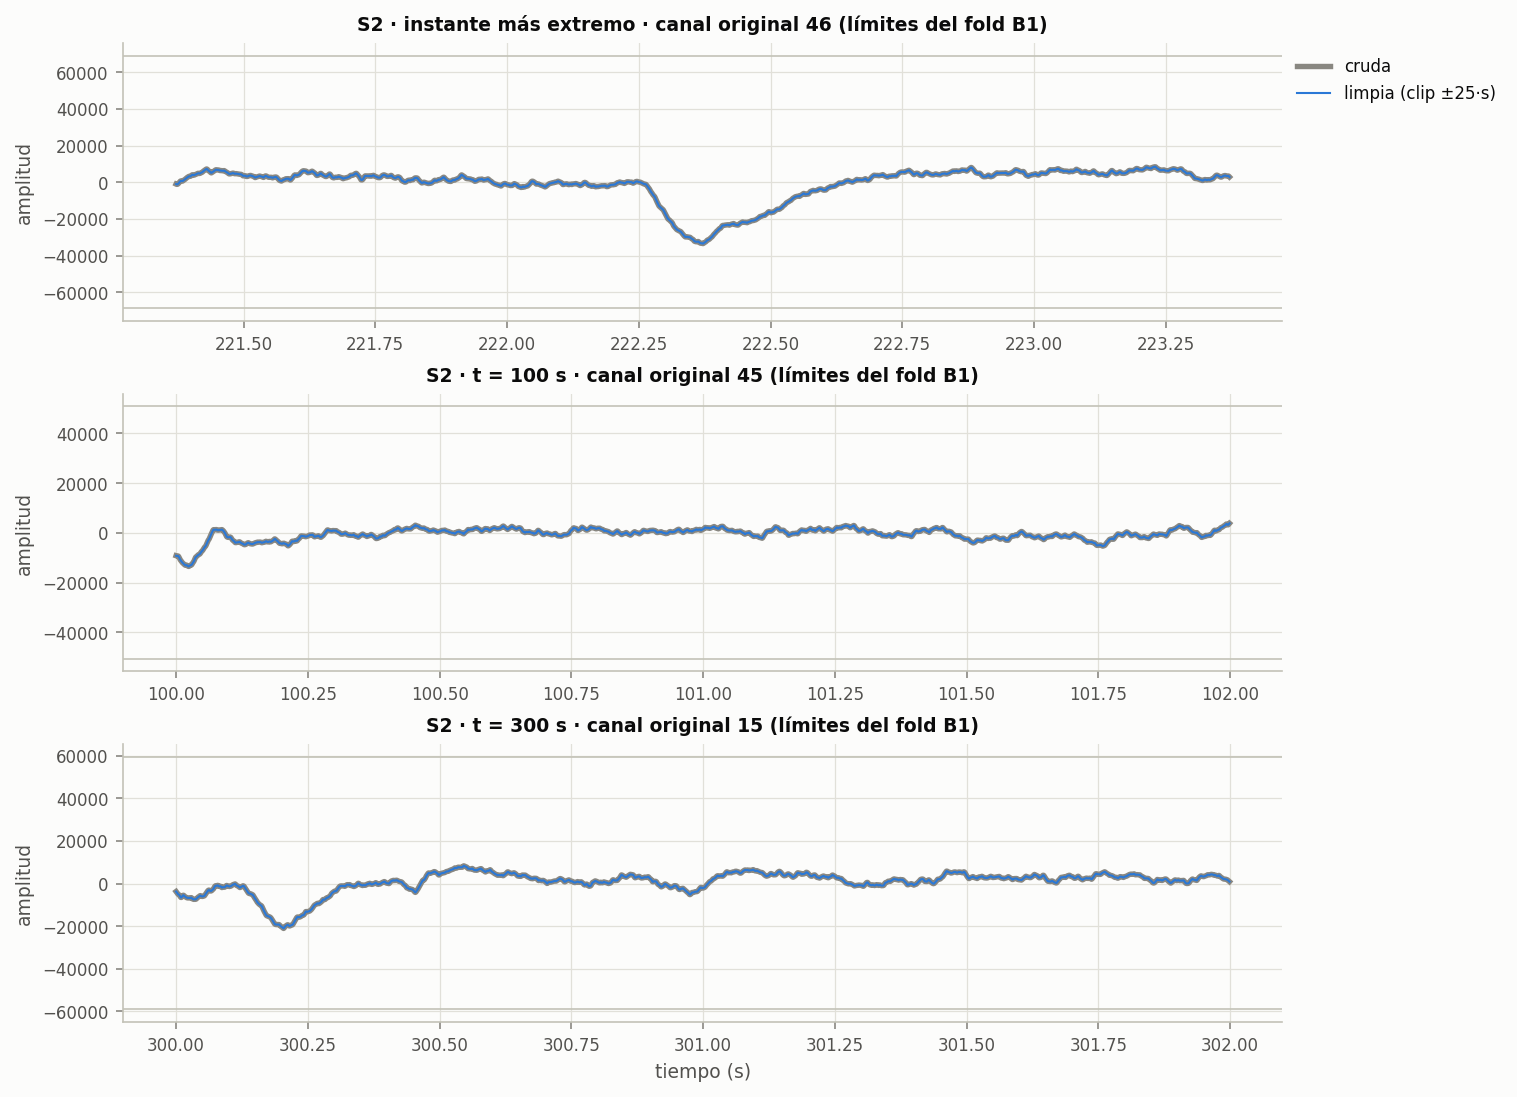

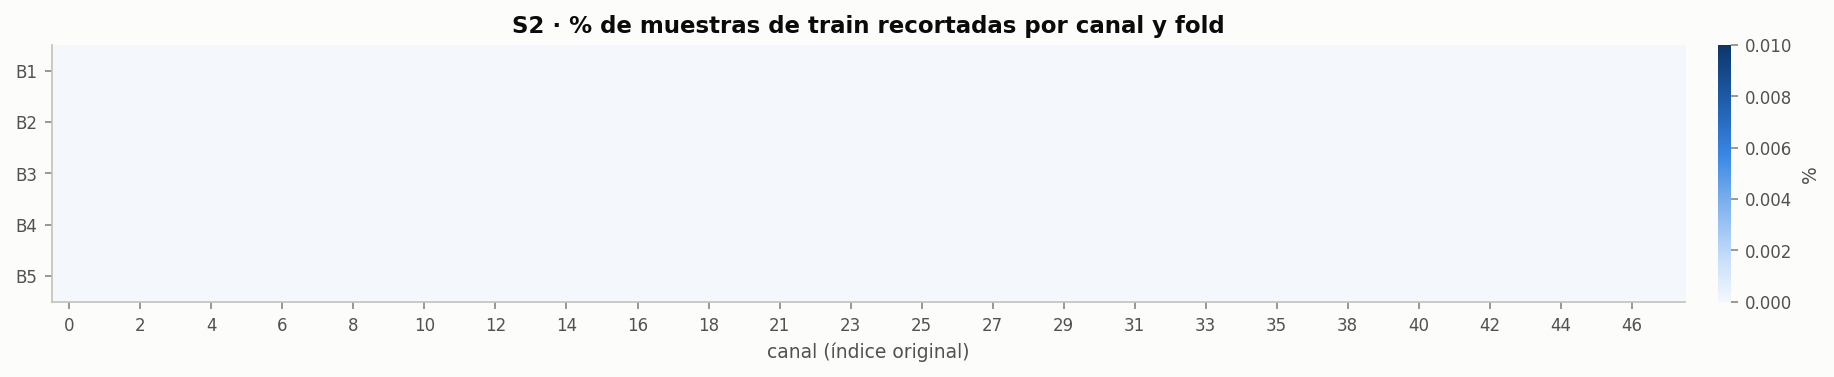

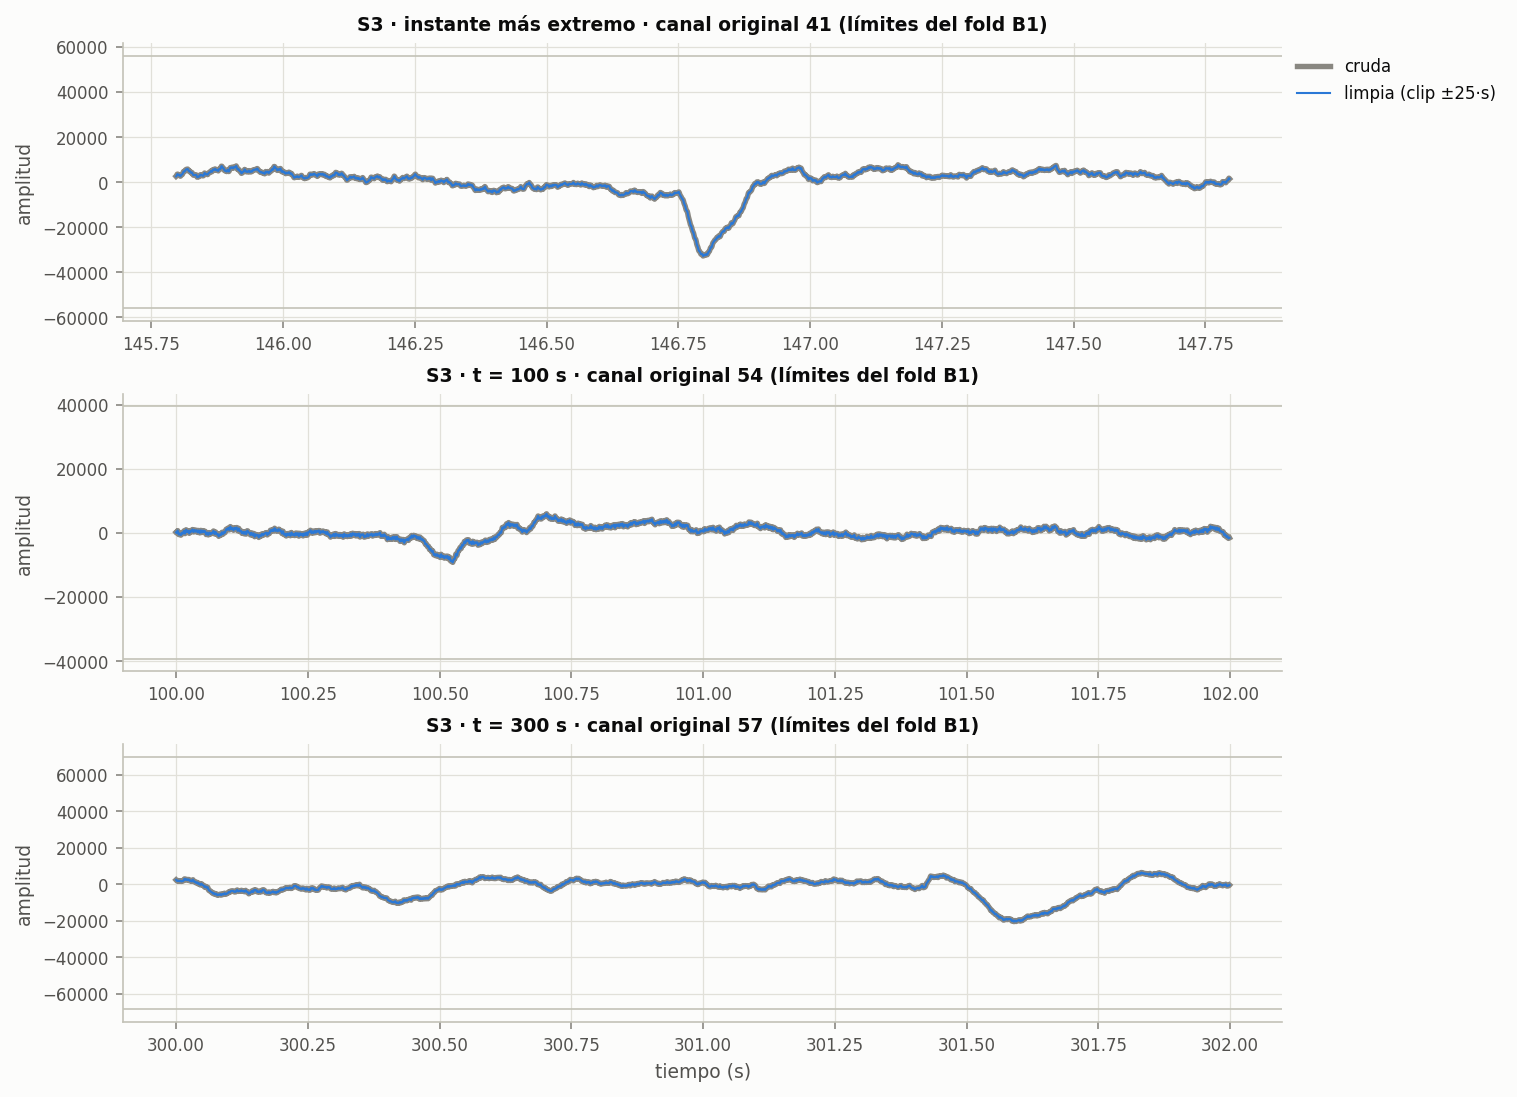

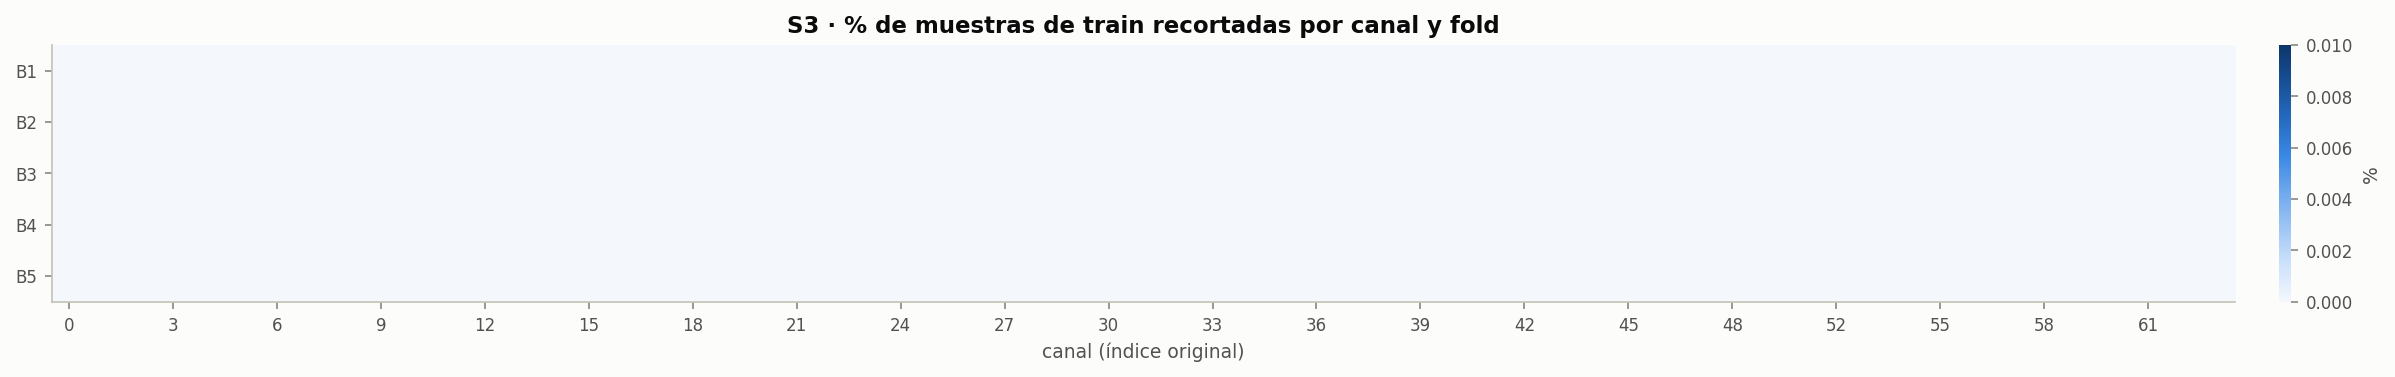

In [5]:
!cd "{REPO_DIR}" && python scripts/run_experiments.py --quality --data-dir "{DATA_DIR}" --results-dir "{RESULTS_DIR}" 2>&1 | tail -4

import pandas as pd
from IPython.display import display
Q = f"{RESULTS_DIR}/quality"
display(pd.read_csv(f"{Q}/channels.csv"))
display(pd.read_csv(f"{Q}/glove_hold.csv"))
display(pd.read_csv(f"{Q}/finite_and_clipping.csv"))
reporting.show_images([f"{Q}/figures/filter_responses.png"]
                      + [f"{Q}/figures/{s}_{kind}.png" for s in SUBJECTS for kind in ("raw_vs_clean", "clip_fraction")])

## 6. Smoke real (1 época × 2 batches, S1/B1)
Recorre la cadena completa con datos reales en `RESULTS_DIR/_smoke` (separado de la campaña) y estima el tiempo de cómputo. El primer batch incluye el calentamiento de CUDA, así que la estimación es conservadora.

In [6]:
!cd "{REPO_DIR}" && python scripts/run_experiments.py --smoke --data-dir "{DATA_DIR}" --results-dir "{RESULTS_DIR}" 2>&1 | grep -v Warning | tail -25

import glob, json
import pandas as pd
from IPython.display import display
rows = []
for path in glob.glob(f"{RESULTS_DIR}/_smoke/runs/*/S1/B1/history.csv"):
    h = pd.read_csv(path)
    rows.append({"variante": path.split("/")[-4], "s_por_batch": h.train_seconds.iloc[-1] / h.n_batches.iloc[-1],
                 "s_validación": h.val_seconds.iloc[-1]})
est = pd.DataFrame(rows).set_index("variante").sort_index()
batches = 29500 // CFG["training"]["batch_size"]
est["min_por_fit"] = CFG["training"]["epochs"] * (batches * est.s_por_batch + est["s_validación"]) / 60
display(est.round(3))
feat = [json.load(open(p))["compute_seconds"] for p in glob.glob(f"{RESULTS_DIR}/_smoke/quality/features/*.json")]
hours = (est.min_por_fit.mean() * 135 + 90 * sum(feat) / max(len(feat), 1) / 60) / 60
print(f"campaña completa estimada: ~{hours:.1f} h de GPU (orientativo)")

2026-10-28 02:13:55 INFO NumExpr defaulting to 12 threads.
2026-10-28 02:14:09 INFO campaña: 9 corridas planificadas, 0 pendientes; dispositivo cuda
2026-10-28 02:14:10 INFO [S1 B1] nada pendiente
2026-10-28 02:14:10 INFO campaña terminada


,s_por_batch,s_validación,min_por_fit
variante,,,
A1,0.351,0.141,67.342
A2,0.351,0.143,67.304
A3,0.030,0.010,5.793
A4,0.141,0.058,27.075
A5,0.019,0.011,3.683
P0,0.642,0.154,123.130
P1,0.366,0.143,70.174
P3,0.372,0.143,71.336
P5,0.364,0.143,69.907


campaña completa estimada: ~126.6 h de GPU (orientativo)


In [8]:
import time, torch, torch.nn.functional as F
from ecog_ablations import models
from ecog_ablations.config import load_config
from ecog_ablations.training import configure_torch
cfg = load_config(); configure_torch(cfg["runtime"])
dev = torch.device("cuda"); x = torch.randn(128, 63 * 40, 256, device=dev)

def step(arch, n=10):
    torch.manual_seed(0)
    m = models.build_model(arch, cfg, 63 * 40).to(dev)
    for i in range(n + 2):  # 2 de calentamiento
        if i == 2: torch.cuda.synchronize(); t0 = time.perf_counter()
        m.zero_grad(set_to_none=True); m(x).square().mean().backward()
    torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n, [p.grad.clone() for p in m.parameters()]

t_new, g1 = step("A0"); _, g2 = step("A0")
print(f"linear_upsample: {t_new:.3f} s/paso; gradientes idénticos: {all(torch.equal(a, b) for a, b in zip(g1, g2))}")
models.linear_upsample = lambda t, size: F.interpolate(t, size=size, mode="linear", align_corners=False)
print(f"F.interpolate:   {step('A0')[0]:.3f} s/paso")


linear_upsample: 0.068 s/paso; gradientes idénticos: True


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: upsample_linear1d_backward_out_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


F.interpolate:   0.812 s/paso


## 7. Lanzar la campaña en segundo plano
El entrenamiento corre como un proceso independiente en el servidor, con el log en `RESULTS_DIR/logs/`. Si ya hay un runner vivo en este servidor, el nuevo se niega a arrancar.

In [4]:
import subprocess, sys, time
os.makedirs(f"{RESULTS_DIR}/logs", exist_ok=True)
LOG_PATH = f"{RESULTS_DIR}/logs/runner_{time.strftime('%Y%m%d_%H%M%S')}.log"
args = [sys.executable, "-u", f"{REPO_DIR}/scripts/run_experiments.py", "--data-dir", DATA_DIR,
        "--results-dir", RESULTS_DIR, "--subjects", *SUBJECTS, "--folds", *FOLDS]
if VARIANTS:
    args += ["--variants", *VARIANTS]
PROC = subprocess.Popen(args, stdout=open(LOG_PATH, "a"), stderr=subprocess.STDOUT, cwd=REPO_DIR,
                        start_new_session=True)
time.sleep(20)
print("PID", PROC.pid, "| estado:", "en marcha" if PROC.poll() is None else f"terminó (código {PROC.returncode})")
print("log:", LOG_PATH, "  (en la terminal de Colab: tail -f", LOG_PATH + ")")
print(open(LOG_PATH).read()[-2000:])

PID 1568 | estado: en marcha
log: /content/drive/MyDrive/ECoG_Architectures_Exploration/results/logs/runner_20261028_134744.log   (en la terminal de Colab: tail -f /content/drive/MyDrive/ECoG_Architectures_Exploration/results/logs/runner_20261028_134744.log)
2026-10-28 13:47:45 INFO NumExpr defaulting to 12 threads.



## 8. Monitor (reejecutable)
Se refresca cada `refresh` segundos y muestra:
- progreso y ETA;
- curva en vivo de la corrida activa;
- resultados parciales por variante y sujeto, y deltas apareadas parciales;
- últimas líneas del log.

**Detener esta celda (■) no detiene el entrenamiento.**

In [5]:
reporting.monitor(RESULTS_DIR, CFG, SUBJECTS, FOLDS, VARIANTS, refresh=10)

2026-10-28 16:27:02 · completadas 135/135 ·  · tiempo restante estimado: 0 h 00 min
runner 48d16084ab53-8119: último latido hace 18036 s · [P3 S3 B4]
runner 501627e217ce-20597: último latido hace 51334 s · [P0 S1 B1]


state,completed
variant,
P0,15
P1,15
P3,15
P5,15
A1,15
A2,15
A3,15
A4,15
A5,15


Pearson macro medio (folds completados):


subject,S1,S2,S3,global
variant,,,,
P0,0.4990,0.4289,0.7187,0.5489
P1,0.5071,0.5445,0.7142,0.5886
P3,0.5289,0.4322,0.7106,0.5572
P5,0.5128,0.4235,0.7132,0.5498
A1,0.5278,0.5223,0.7781,0.6094
A2,0.5619,0.5291,0.7747,0.6219
A3,0.4752,0.3947,0.6820,0.5173
A4,0.5034,0.4736,0.7648,0.5806
A5,0.6038,0.6216,0.8258,0.6837


Δ apareada frente al control (media):


subject,S1,S2,S3,global
comparison,,,,
P1 − P0,0.0081,0.1157,-0.0046,0.0397
P3 − P0,0.0300,0.0033,-0.0081,0.0084
P5 − P0,0.0138,-0.0054,-0.0056,0.0009
A1 − P0,0.0288,0.0934,0.0593,0.0605
A2 − P0,0.0629,0.1002,0.0560,0.0731
A3 − P0,-0.0238,-0.0342,-0.0368,-0.0316
A4 − P0,0.0045,0.0447,0.0460,0.0317
A5 − P0,0.1048,0.1927,0.1070,0.1349


— últimas líneas de runner_20261028_134744.log —
2026-10-28 16:22:54 INFO [P5 S3 B5] época 42/50  train 0.0027  val 0.0366  r_val 0.6791  (7.3 s)
2026-10-28 16:23:02 INFO [P5 S3 B5] época 43/50  train 0.0026  val 0.0380  r_val 0.6680  (7.3 s)
2026-10-28 16:23:09 INFO [P5 S3 B5] época 44/50  train 0.0027  val 0.0371  r_val 0.6766  (7.3 s)
2026-10-28 16:23:16 INFO [P5 S3 B5] época 45/50  train 0.0026  val 0.0370  r_val 0.6762  (7.4 s)
2026-10-28 16:23:24 INFO [P5 S3 B5] época 46/50  train 0.0026  val 0.0366  r_val 0.6821  (7.3 s)
2026-10-28 16:23:31 INFO [P5 S3 B5] época 47/50  train 0.0025  val 0.0362  r_val 0.6821  (7.4 s)
2026-10-28 16:23:39 INFO [P5 S3 B5] época 48/50  train 0.0025  val 0.0375  r_val 0.6782  (7.3 s)
2026-10-28 16:23:46 INFO [P5 S3 B5] época 49/50  train 0.0024  val 0.0385  r_val 0.6701  (7.3 s)
2026-10-28 16:23:53 INFO [P5 S3 B5] época 50/50  train 0.0025  val 0.0373  r_val 0.6744  (7.3 s)
2026-10-28 16:23:53 INFO [P5 S3 B5] completada: Pearson macro 0.6744 (369 s)
2

: 

: 

## 9. Detener la campaña
Envía SIGINT al runner: la corrida en curso queda `interrupted` y se reentrenará al relanzar (celda 7, o la 11 en la campaña complementaria).

In [4]:
import glob, json, signal, socket
for path in glob.glob(f"{RESULTS_DIR}/runners/{socket.gethostname()}-*.json"):
    pid = json.load(open(path))["pid"]
    try:
        os.killpg(os.getpgid(pid), signal.SIGINT)
        print("SIGINT enviado al runner", pid)
    except ProcessLookupError:
        print("el runner", pid, "ya no existe")

## 10. Reporte
Genera `RESULTS_DIR/summary/` (CSV y figuras) con las corridas disponibles. Se puede ejecutar a mitad de campaña.

    "pearson_per_finger": "/content/drive/MyDrive/ECoG_Architectures_Exploration/results/summary/figures/pearson_per_finger.png",
    "training_curves": "/content/drive/MyDrive/ECoG_Architectures_Exploration/results/summary/figures/training_curves.png",
    "example_predictions": "/content/drive/MyDrive/ECoG_Architectures_Exploration/results/summary/figures/example_predictions_P0.png"
  },
  "equivalence_checked": 30,
  "equivalence_failed": 0
}

Pearson macro medio por variante y sujeto:
subject      S1      S2      S3  global
variant                                
P0       0.4990  0.4289  0.7187  0.5489
P1       0.5071  0.5445  0.7142  0.5886
P3       0.5289  0.4322  0.7106  0.5572
P5       0.5128  0.4235  0.7132  0.5498
A1       0.5278  0.5223  0.7781  0.6094
A2       0.5619  0.5291  0.7747  0.6219
A3       0.4752  0.3947  0.6820  0.5173
A4       0.5034  0.4736  0.7648  0.5806
A5       0.6038  0.6216  0.8258  0.6837


,comparison,kind,variant,subject,n_pairs,n_invalid,delta_mean,delta_sd,n_positive,n_subjects
24,P1 − P0,principal,P1,global,15,0,0.0397,0.0661,12,3.0
25,P3 − P0,principal,P3,global,15,0,0.0084,0.0196,9,3.0
26,P5 − P0,principal,P5,global,15,0,0.0009,0.0112,7,3.0
27,A1 − P0,principal,A1,global,15,0,0.0605,0.0323,15,3.0
28,A2 − P0,principal,A2,global,15,0,0.0731,0.0238,15,3.0
29,A3 − P0,principal,A3,global,15,0,-0.0316,0.0069,2,3.0
30,A4 − P0,principal,A4,global,15,0,0.0317,0.0236,11,3.0
31,A5 − P0,descriptiva (multicomponente),A5,global,15,0,0.1349,0.0501,14,3.0


,,rel_max_diff,corr,equivalent
preprocessing,reference,,,
P2,P1,1.303865e-09,1.000000,True
P4,P1,2.055651e-07,1.000000,True
P5,P3,1.464766e-01,0.912122,False


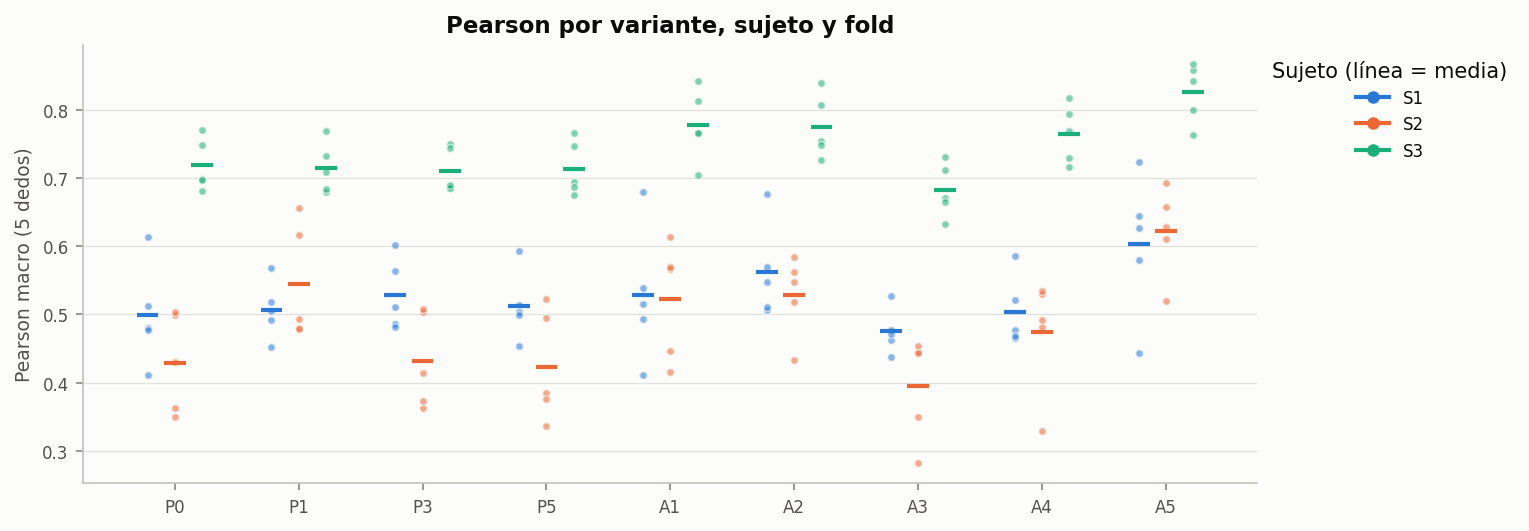

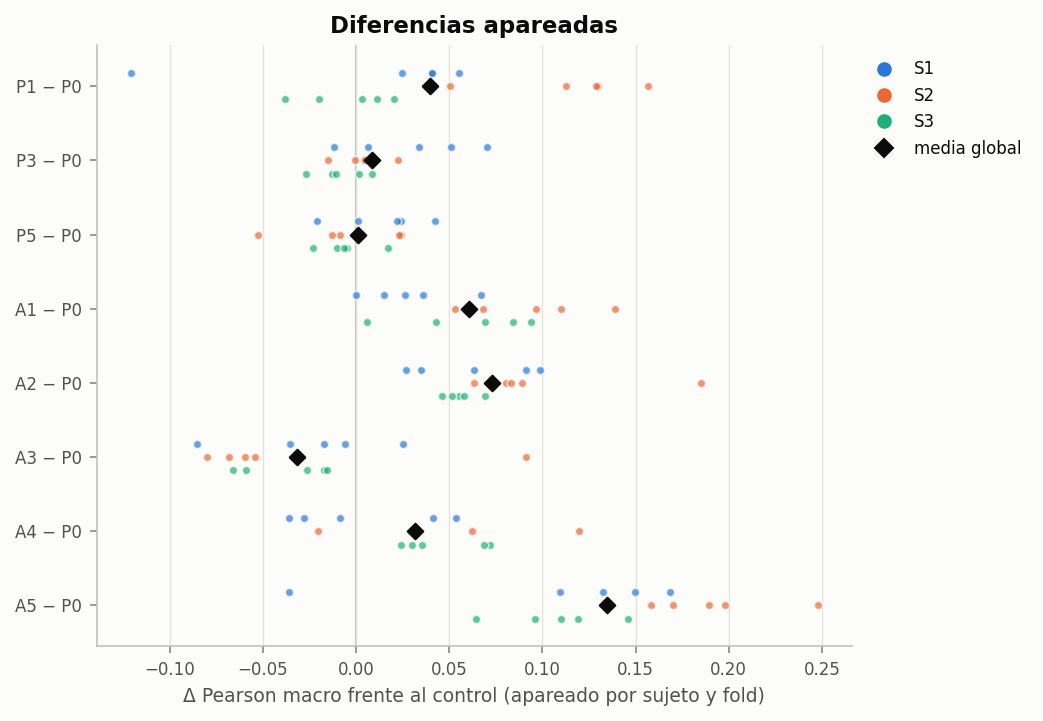

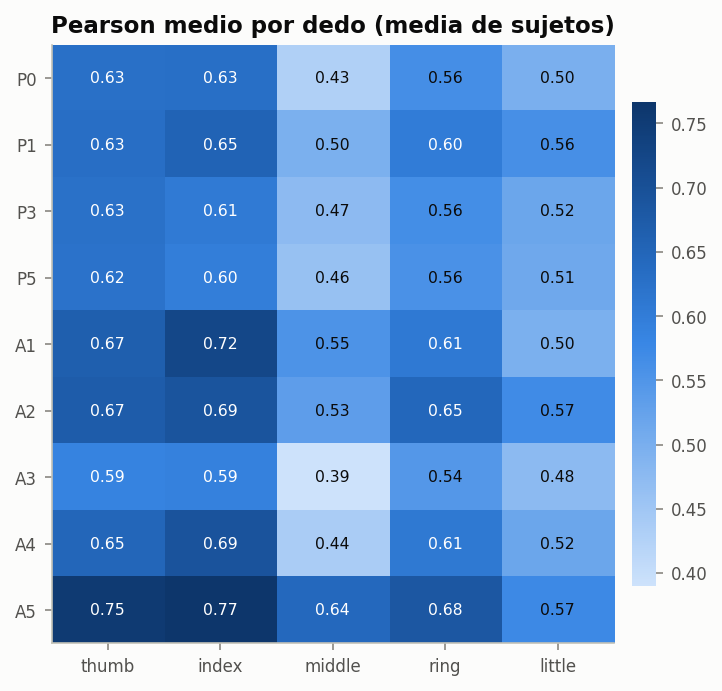

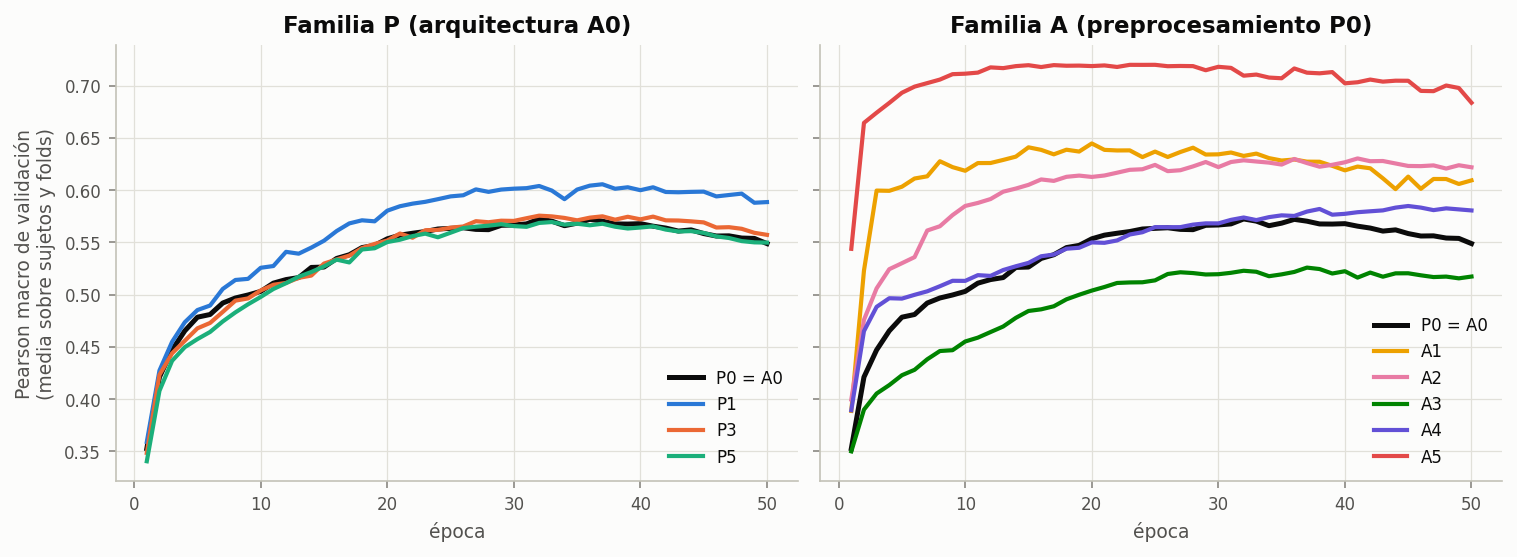

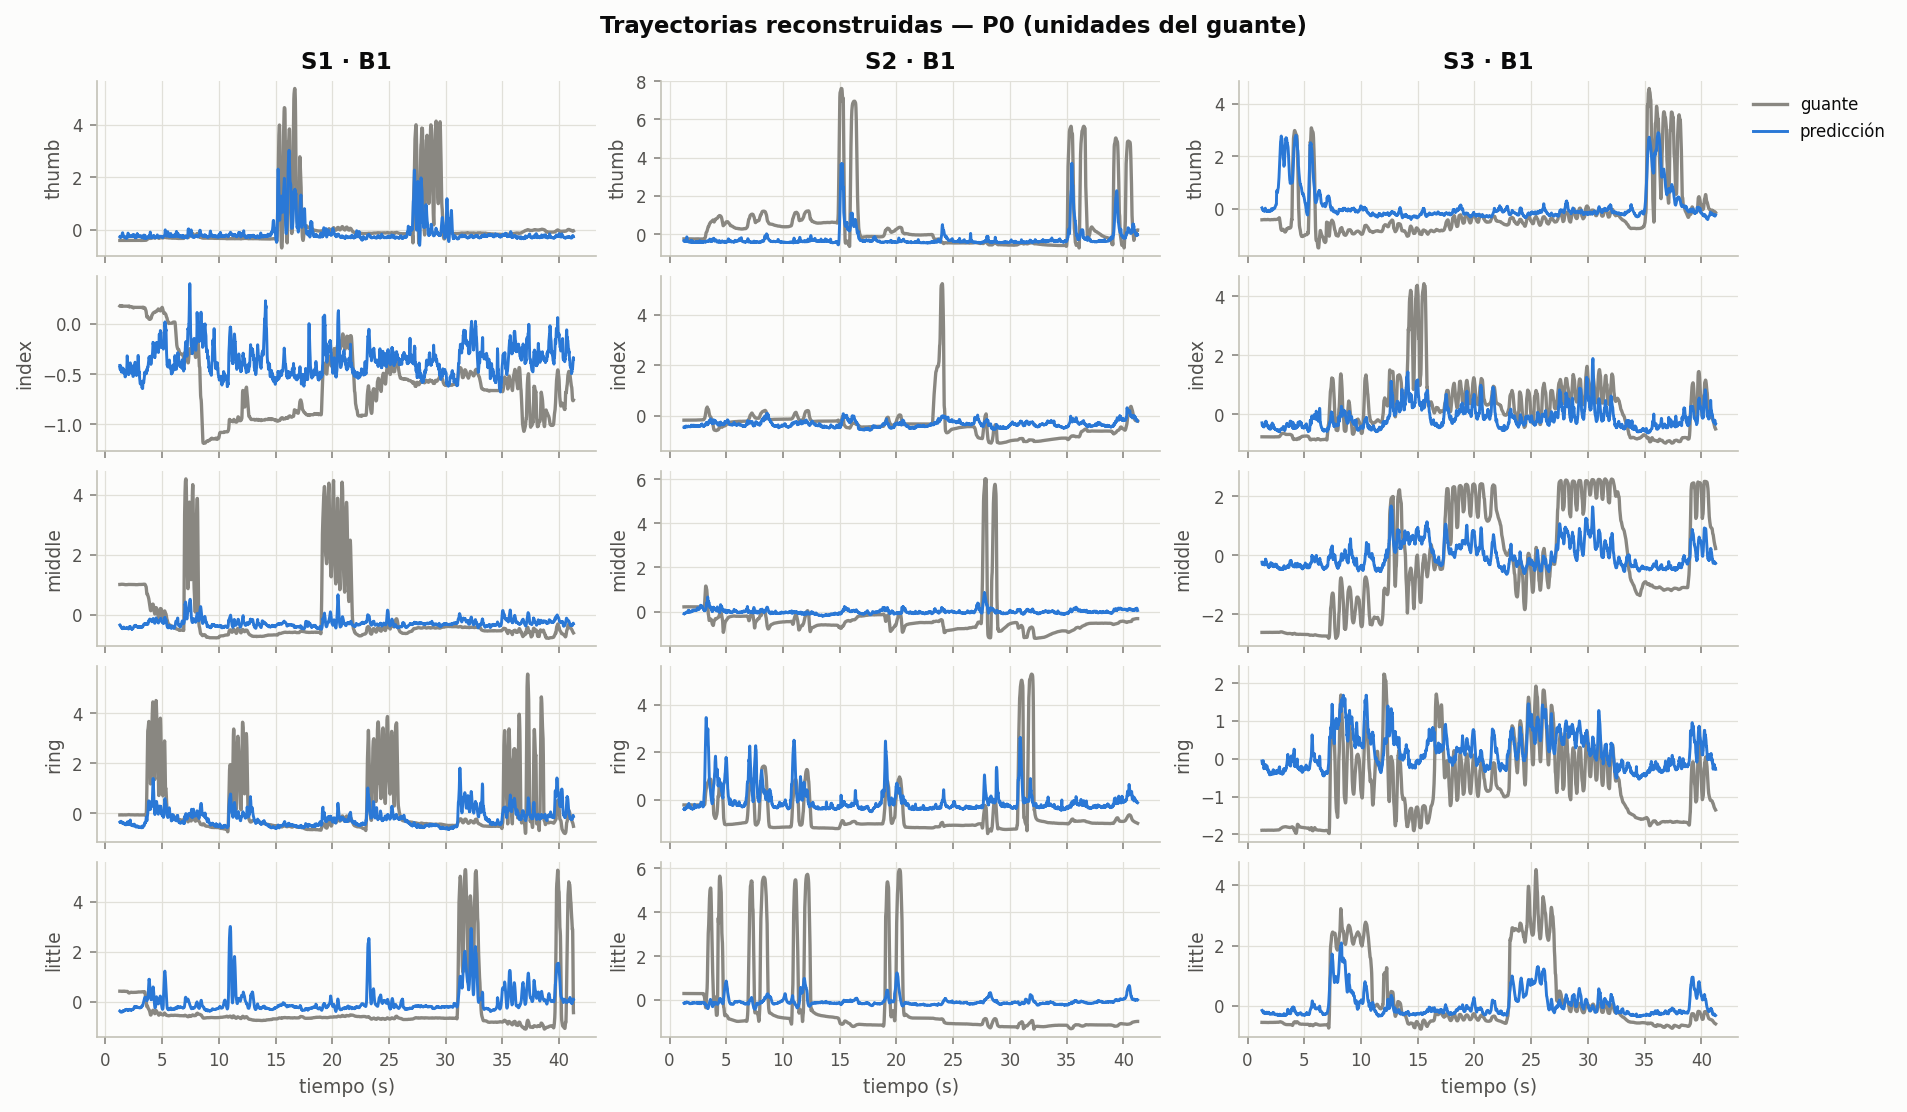

In [5]:
!cd "{REPO_DIR}" && python scripts/make_report.py --results-dir "{RESULTS_DIR}" 2>&1 | tail -20

import pandas as pd
from IPython.display import display
S = f"{RESULTS_DIR}/summary"
_, deltas = reporting.paired_deltas(reporting.collect_runs(RESULTS_DIR, CFG), CFG)
if not deltas.empty:
    display(deltas[deltas.subject == "global"].round(4))
equivalence = reporting.collect_equivalence(RESULTS_DIR)
if not equivalence.empty:
    display(equivalence.groupby(["preprocessing", "reference"])[["rel_max_diff", "corr", "equivalent"]]
            .agg({"rel_max_diff": "max", "corr": "min", "equivalent": "all"}))
reporting.show_images([f"{S}/figures/{n}.png" for n in
                       ("pearson_by_variant", "paired_deltas", "pearson_per_finger", "training_curves", "example_predictions_P0")])

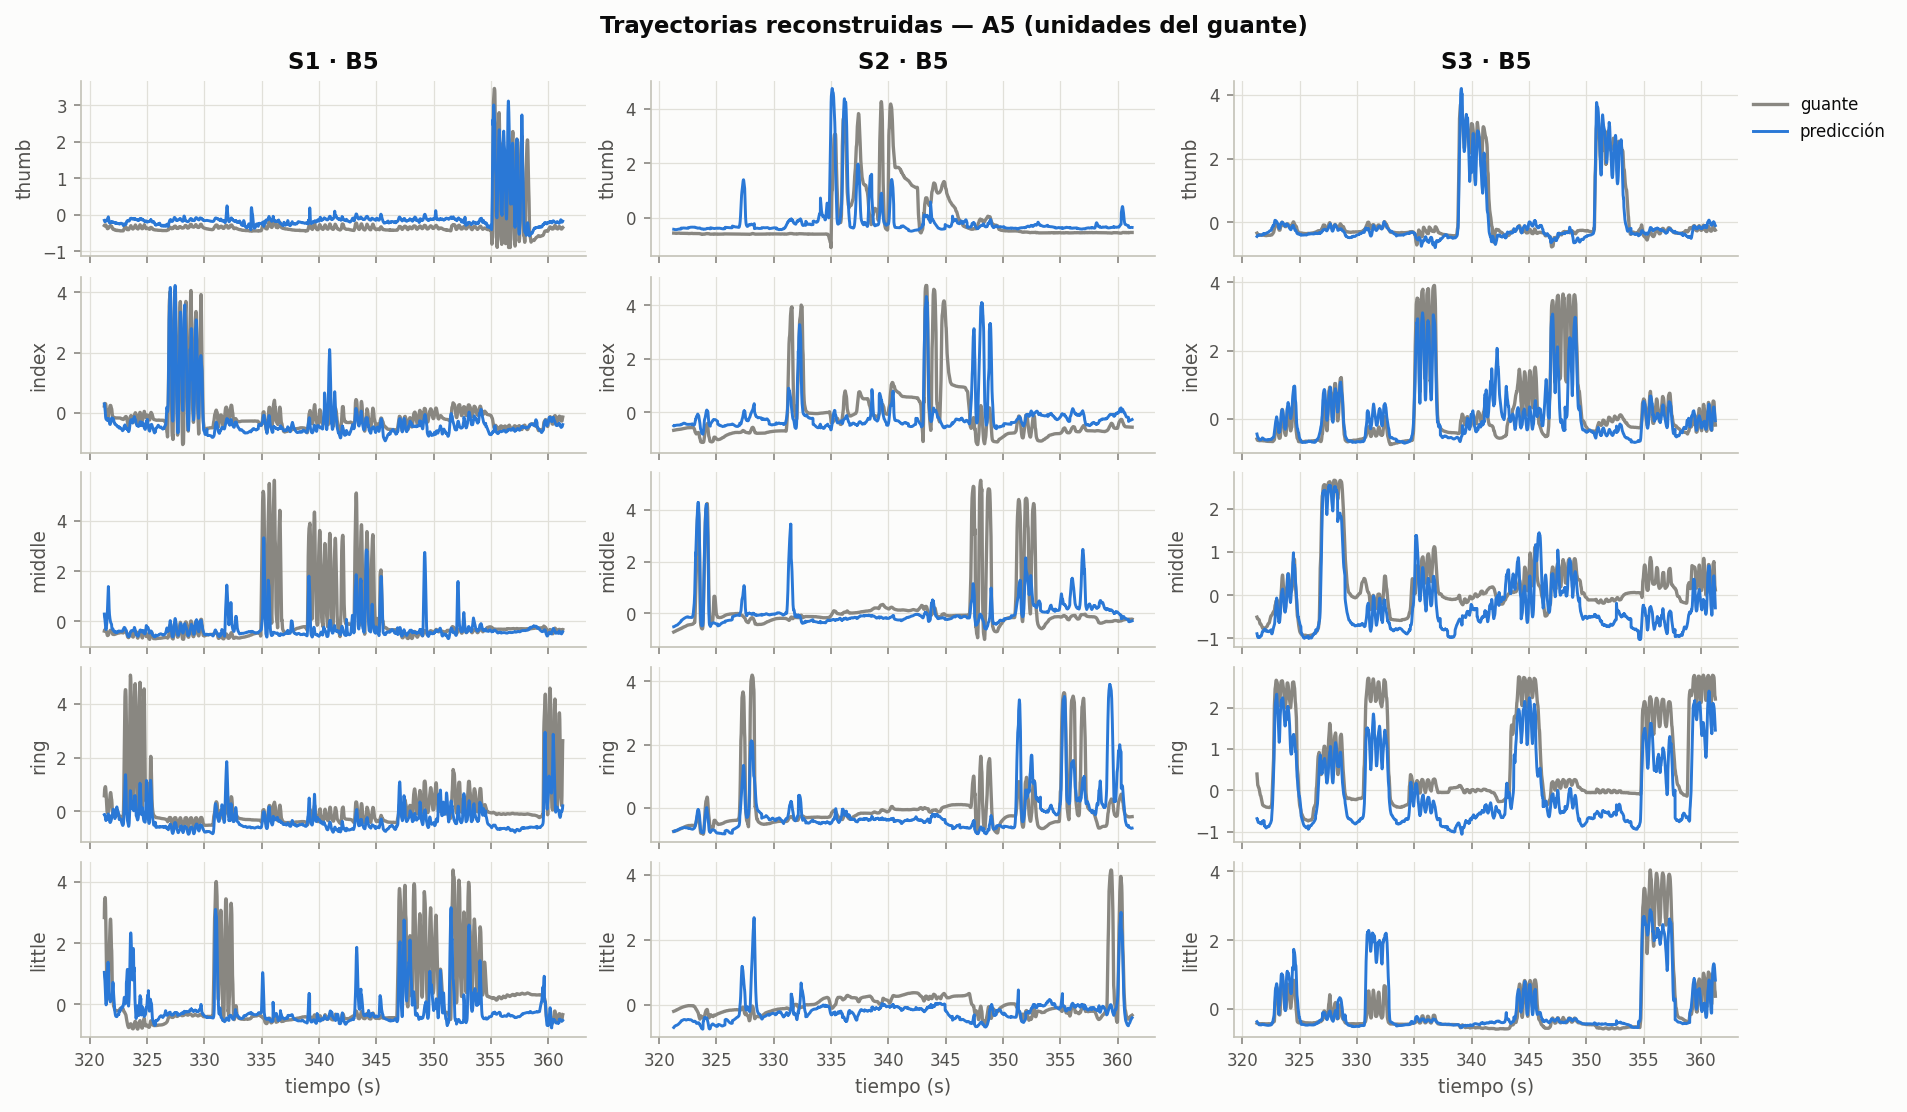

In [16]:
from pathlib import Path

VARIANT, FOLD = "A5", "B5"   # FOLD: B1–B5
fig = reporting.plot_example_predictions(
    RESULTS_DIR, CFG, Path(RESULTS_DIR) / "summary" / "figures" / f"example_predictions_{VARIANT}_{FOLD}.png",
    variant=VARIANT, fold=FOLD, seconds=40.0)
if fig:
    reporting.show_images([fig])
else:
    print(f"todavía no hay predictions.npz de {VARIANT} en {FOLD}")


## 11. Campaña complementaria: descomposición de A5 (30 entrenamientos)
Análisis **posterior**, decidido con resultados parciales (plan, sección 12): no modifica los 135 entrenamientos ni sus comparaciones.

| ID | Normalización | Dropout | Upsampling | Decoder | Equivale a |
|---|---|---|---|---|---|
| A5a | LayerNorm | 0.1 | interpolación | upsample → conv → concat | A1 + A2 |
| A5b | LayerNorm | 0.1 | interpolación | upsample → concat → conv | A1 + A2 + A4 (A5 sin ConvTranspose) |

La cadena A0 → A5a → A5b → A5 añade un componente por paso. Los contrastes están fijados en `configs/experiment.yaml` y se aparean por sujeto y fold:
- **Pasos** (suman A5 − P0): `A5a − P0`, `A5b − A5a`, `A5 − A5b`.
- **Interacciones** (paso menos el efecto aislado del mismo componente sobre A0): `A5a − A1 − A2 + P0`, `(A5b − A5a) − (A4 − P0)`, `(A5 − A5b) − (A3 − P0)`.

**Requisitos**
1. La campaña principal ha terminado. La primera celda se niega a lanzar si quedan corridas principales pendientes o en marcha (las fallidas se permiten).
2. El servidor tiene el código que define A5a/A5b: haz commit y push (o crea una etiqueta nueva en `GIT_REF`) y reejecuta la celda 3. **No lo hagas mientras el runner principal siga vivo**: cada corrida registra en su `config.json` el commit del servidor.

Se detiene con la sección 9. Si el servidor se recicla, ejecuta las celdas 1–3 y vuelve a esta sección: las corridas completadas se saltan.

In [ ]:
# Lanzar A5a/A5b en segundo plano (mismo runner que la celda 7)
import subprocess, sys, time
missing = [v for v in EXTRA_VARIANTS if v not in CFG["variants"]]
assert not missing, f"el código del servidor no define {missing}: haz push y reejecuta la celda 3"
principal = reporting.plan_status(RESULTS_DIR, CFG, SUBJECTS, FOLDS, [v for v in CFG["variants"] if v not in EXTRA_VARIANTS])
unfinished = principal[~principal.state.isin(["completed", "failed"])]
assert unfinished.empty, f"la campaña principal no ha terminado: {unfinished.state.value_counts().to_dict()}"
print("campaña principal:", principal.state.value_counts().to_dict())

os.makedirs(f"{RESULTS_DIR}/logs", exist_ok=True)
LOG_PATH = f"{RESULTS_DIR}/logs/runner_a5_{time.strftime('%Y%m%d_%H%M%S')}.log"
args = [sys.executable, "-u", f"{REPO_DIR}/scripts/run_experiments.py", "--data-dir", DATA_DIR,
        "--results-dir", RESULTS_DIR, "--subjects", *SUBJECTS, "--folds", *FOLDS, "--variants", *EXTRA_VARIANTS]
PROC = subprocess.Popen(args, stdout=open(LOG_PATH, "a"), stderr=subprocess.STDOUT, cwd=REPO_DIR,
                        start_new_session=True)
time.sleep(20)
print("PID", PROC.pid, "| estado:", "en marcha" if PROC.poll() is None else f"terminó (código {PROC.returncode})")
print("log:", LOG_PATH, "  (en la terminal de Colab: tail -f", LOG_PATH + ")")
print(open(LOG_PATH).read()[-2000:])

In [ ]:
# Monitor de A5a/A5b (reejecutable; detenerlo no detiene el entrenamiento)
reporting.monitor(RESULTS_DIR, CFG, SUBJECTS, FOLDS, EXTRA_VARIANTS, refresh=10)

In [ ]:
# Reporte con A5a/A5b: pasos e interacciones de la descomposición de A5
!cd "{REPO_DIR}" && python scripts/make_report.py --results-dir "{RESULTS_DIR}" 2>&1 | tail -20

import pandas as pd
from IPython.display import display
S = f"{RESULTS_DIR}/summary"
_, contrast_summary = reporting.contrasts(reporting.collect_runs(RESULTS_DIR, CFG), CFG)
if not contrast_summary.empty:
    print("Contraste medio por sujeto (global = media de sujetos):")
    display(contrast_summary.pivot_table(index="comparison", columns="subject", values="delta_mean", sort=False).round(4))
    display(contrast_summary[contrast_summary.subject == "global"].set_index("comparison")
            [["label", "kind", "n_pairs", "n_invalid", "delta_mean", "delta_sd", "n_positive"]].round(4))
reporting.show_images([f"{S}/figures/{n}.png" for n in ("contrasts", "training_curves", "pearson_by_variant")])

## 12. Al terminar la sesión
Fuerza la sincronización de Drive antes de liberar el servidor (*Colab: Remove Server*). Colab escribe en Drive a través de una caché.

In [6]:
try:
    drive.flush_and_unmount()
    print("Drive sincronizado y desmontado")
except Exception as exc:  # p. ej. si Drive se montó desde el comando de la extensión
    print("no se pudo desmontar Drive:", exc)

Drive sincronizado y desmontado
